## BAB 9 — PEMROSESAN BAHASA ALAMI & LARGE LANGUAGE MODEL

### A. Pilihan Ganda 

#### 1. Representasi teks yang menghitung kemunculan kata dan mengabaikan urutan disebut…
- [ ] (a) tokenisasi
- [x] **(b) bag of words**
- [ ] (c) stemming
- [ ] (d) transformer

#### 2. Fungsi Laplace smoothing (+1) pada Naive Bayes adalah…
- [ ] (a) mempercepat
- [x] **(b) mencegah peluang nol akibat kata tak dikenal**
- [ ] (c) menghapus stopword
- [ ] (d) mengurutkan kata

#### 3. Inti cara kerja LLM adalah…
- [ ] (a) mencari di database
- [x] **(b) menebak kata berikutnya**
- [ ] (c) mencocokkan aturan IF–THEN
- [ ] (d) menghitung centroid

#### 4. Arsitektur JST yang menjadi fondasi LLM adalah…
- [ ] (a) CNN
- [ ] (b) perceptron
- [x] **(c) transformer**
- [ ] (d) decision tree

#### 5. Teknik menyuntikkan sumber terpercaya ke prompt agar jawaban terikat fakta disebut…
- [ ] (a) stemming
- [ ] (b) few-shot
- [x] **(c) RAG**
- [ ] (d) fine-tuning

### B. Esai

### 1. Dengan data latih Subbab 9.2, klasifikasikan pesan “gratis kuliah” — tuliskan peluang tiap kata dan skor kedua kelas. (Petunjuk: hasilnya menarik — jelaskan mengapa.)
#### Peluang Tiap Kata
| Kata | Muncul di SPAM | $P(\text{kata} \mid \text{spam})$ | Muncul di HAM | $P(\text{kata} \mid \text{ham})$ |
| :--- | :---: | :---: | :---: | :---: |
| **gratis** | 2 | $(2+1)/15 = \mathbf{3/15 \ (0{,}200)}$ | 0 | $(0+1)/15 = \mathbf{1/15 \ (0{,}067)}$ |
| **kuliah** | 0 | $(0+1)/15 = \mathbf{1/15 \ (0{,}067)}$ | 2 | $(2+1)/15 = \mathbf{3/15 \ (0{,}200)}$ |

#### Perhitungan Skor Kelas
* **Skor SPAM:**  
  $$P(\text{spam}) \times P(\text{gratis} \mid \text{spam}) \times P(\text{kuliah} \mid \text{spam})$$
  $$= 0{,}5 \times \frac{3}{15} \times \frac{1}{15} = 0{,}5 \times 0{,}200 \times 0{,}067 = \mathbf{0{,}00667}$$

* **Skor HAM:**  
  $$P(\text{ham}) \times P(\text{gratis} \mid \text{ham}) \times P(\text{kuliah} \mid \text{ham})$$
  $$= 0{,}5 \times \frac{1}{15} \times \frac{3}{15} = 0{,}5 \times 0{,}067 \times 0{,}200 = \mathbf{0{,}00667}$$

#### Mengapa Hasilnya Menarik?
* **Skornya Seri (Tie):** Kedua kelas bernilai persis sama, yaitu **$0{,}00667$**.
* **Saling Meniadakan:** Kata `"gratis"` sangat khas spam ($3/15$ vs $1/15$), tapi kata `"kuliah"` khas ham dengan kekuatan yang seimbang ($3/15$ vs $1/15$). Karena peluang awal (*prior*) sama-sama $0{,}5$, nilainya saling menetralkan.
* **Solusi Praktis:** Model tidak bisa memilih (50:50). Di sistem filter email nyata, jika terjadi seri, pesan dimasukkan ke **HAM** agar informasi kampus tidak terbuang ke spam (*mencegah false positive*).


### 2. Jelaskan mengapa bag of words gagal membedakan “bukan spam” dari “spam”, dan bagaimana model berbasis urutan (transformer) mengatasinya secara konseptual.
* **Kenapa Bag of Words (BoW) Gagal?**  
  BoW hanya menghitung jumlah kata tanpa peduli urutan. Pada kalimat `"bukan spam"`, BoW tetap menangkap kata `"spam"` dengan bobot tinggi. BoW tidak tahu kalau kata `"bukan"` di depannya membalikkan makna kalimat.
* **Bagaimana Transformer Mengatasinya?**  
  Transformer menggunakan **Positional Encoding** (mencatat posisi tiap kata) dan **Self-Attention** (menghubungkan konteks antar kata). Model paham bahwa kata `"bukan"` berpasangan langsung dengan `"spam"`, sehingga maknanya adalah non-spam (HAM).

### 3. Tulis ulang prompt buruk “buatkan makalah AI” menjadi prompt baik dengan kelima komponen (peran, konteks, tugas, batasan, format) untuk konteks tugas kuliahmu.
* **Prompt Buruk:**  
  > *"buatkan makalah AI"*

* **Prompt Baik:**
  * **Peran:** Asisten dosen mata kuliah Sistem Cerdas.
  * **Konteks:** Mahasiswa Teknik Informatika yang sedang menyusun tugas makalah akhir semester tentang Natural Language Processing (NLP).
  * **Tugas:** Buatkan draf isi makalah akademik berjudul *"Perbandingan Naive Bayes dan Transformer dalam Menangani Negasi Teks pada Filter Spam"*.
  * **Batasan:** Panjang 1.000–1.500 kata, gunakan bahasa Indonesia formal yang jelas, sertakan contoh kasus sederhana, dan jangan mengarang rumus fiktif.
  * **Format:** Pendahuluan (Latar Belakang & Masalah) $\rightarrow$ Pembahasan (Teori, Komparasi, Studi Kasus) $\rightarrow$ Kesimpulan $\rightarrow$ 3 Referensi Pustaka.

### 4. Berikan tiga contoh tugas di mana kamu MEMPERCAYAI jawaban LLM dan tiga tugas di mana kamu WAJIB memverifikasinya; jelaskan alasan pengelompokanmu.
#### Tugas yang bisa dipercaya
1. **Merapikan Kode (Refactoring):** Memperbaiki indentasi, memecah fungsi panjang, atau menambah komentar/docstring.
2. **Brainstorming Ide:** Mencari alternatif judul tugas akhir, topik studi kasus, atau analogi konsep.
3. **Penyusun & Proofreading Bahasa:** Mengecek *typo*, memperbaiki tata bahasa, atau menerjemahkan istilah teknis.

#### Tugas yang wajib diverifikasi manual
1. **Sitasi & Sumber Paper:** LLM rawan berhalusinasi mengarang nama penulis, tahun, atau judul jurnal palsu.
2. **Hitungan Angka & Matematika:** LLM memprediksi teks kata demi kata, bukan kalkulator hitung eksak.
3. **Kode Keamanan & Konfigurasi Server:** Script penanganan password, query database sensitif, atau perintah terminal Linux berisiko tinggi.

#### Alasan pengelompokan
Berdasarkan **risiko kesalahan**:
* Urusan bahasa, format, dan ide punya risiko rendah dan mudah dilihat jika ada salah.
* Fakta ilmiah, hitungan eksak, dan keamanan sistem memiliki risiko fatal jika salah (*LLM sering kali salah tapi dengan nada sangat yakin/halusinasi*).

### 5. Jelaskan pola RAG dan kaitkan dengan prinsip “jujur saat tidak tahu” pada sistem pakar Bab 4 — apa kesamaan filosofinya?
* **Apa itu RAG (Retrieval-Augmented Generation)?**  
  Alih-alih LLM langsung menjawab dari hafalannya, RAG mencari (*retrieve*) dulu dokumen rujukan terpercaya di database, lalu LLM menyusun jawaban (*generate*) hanya berdasarkan dokumen tersebut.
* **Kaitan dengan Bab 4 (Sistem Pakar):**  
  Sistem pakar berbasis aturan (*IF-THEN*) tidak akan menyimpulkan apa pun jika fakta yang dimasukkan pengguna tidak ada dalam basis aturan (*knowledge base*).
* **Kesamaan Filosofi:**  
  Keduanya menganut prinsip **"Hanya menjawab berdasarkan fakta rujukan dan jujur saat tidak tahu"**. Jika data di dokumen tidak ditemukan, RAG menolak berhalusinasi dan langsung menyatakan info tidak tersedia, persis seperti sistem pakar yang berhenti saat tidak ada aturan yang cocok.

## Modul 11 - Algoritma Genetika — Optimasi ala Evolusi (Kasus Tas Kemah 5 kg)

## Integrasi AI

In [ ]:
import io
import os
from dotenv import load_dotenv
from google import genai
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
from PIL import Image

# 1. Muat API key dari file .env
load_dotenv()

# 2. Inisialisasi client (otomatis mendeteksi GEMINI_API_KEY dari .env)
client = genai.Client()


def penjelasan(fig=None, instruksi_tambahan=""):
    """Mengambil grafik aktif, mengirim ke Gemini, dan menampilkan penjelasan Markdown."""
    if fig is None:
        fig = plt.gcf()

    # Validasi kanvas grafik tidak kosong
    if not fig.axes:
        print("Peringatan: Grafik kosong. Panggil penjelasan() sebelum plt.show().")
        return

    # Simpan grafik ke RAM
    buf = io.BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight", dpi=150)
    buf.seek(0)
    img = Image.open(buf)

    # Prompt instruksi
    prompt = f"""
    Jelaskan grafik ini secara sederhana, gunakan bahasa yang mudah dimengerti, 
    hindari istilah teknis yang rumit, dan sertakan contoh atau analogi jika memungkinkan. 
    Gunakan format penjelasan yang menarik dan mudah dibaca.
    {instruksi_tambahan}
    """

    # Model resmi Google GenAI (dengan fallback yang andal)
    daftar_model = ["gemini-3.5-flash", "gemini-3.8-flash", "gemini-flash-latest", "gemini-3.5-flash-lite"]
    response_text = None

    for model_name in daftar_model:
        try:
            response = client.models.generate_content(
                model=model_name, contents=[img, prompt]
            )
            response_text = response.text
            break
        except Exception as e:
            continue
        
    if response_text:
        display(Markdown(response_text))
    else:
        print("Gagal mendapatkan penjelasan dari AI. Silakan coba lagi.")


# 3. Utilitas Format Tabel Bersih & Mudah Dipahami
try:
    from tabulate import tabulate
    def cetak_tabel(data, judul=""):
        """Menampilkan tabel dalam format rounded grid yang rapi dan mudah dibaca."""
        if judul:
            print(f"\n=== {judul} ===")
        print(tabulate(data, headers="keys", tablefmt="rounded_grid", showindex=False))
except ImportError:
    def cetak_tabel(data, judul=""):
        """Fallback jika tabulate belum terpasang."""
        if judul:
            print(f"\n=== {judul} ===")
        import pandas as pd
        if not isinstance(data, pd.DataFrame):
            data = pd.DataFrame(data)
        print(data.to_string(index=False))



### Kegiatan 1 — Kromosom dan Fungsi Fitness (±60 menit)

In [2]:
import random

random.seed(42)  # agar hasil satu kelas seragam

barang = [
    {"nama": "Tenda",        "berat": 2.5, "nilai": 9},
    {"nama": "Sleeping bag", "berat": 1.5, "nilai": 8},
    {"nama": "Kompor mini",  "berat": 1.0, "nilai": 7},
    {"nama": "Power bank",   "berat": 0.5, "nilai": 6},
    {"nama": "Kamera",       "berat": 1.2, "nilai": 5},
    {"nama": "Buku",         "berat": 0.8, "nilai": 2},
    {"nama": "Gitar mini",   "berat": 1.8, "nilai": 4},
    {"nama": "Snack",        "berat": 0.7, "nilai": 3},
]

KAPASITAS = 5.0

def fitness(krom):
    total_berat = 0
    total_nilai = 0
    
    for i in range(len(barang)):
        if krom[i] == 1:  # gen 1 = barang ke-i dibawa
            total_berat += barang[i]["berat"]
            total_nilai += barang[i]["nilai"]
            
    if total_berat > KAPASITAS:
        return 0  # PENALTI: tas jebol = solusi gugur
        
    return total_nilai

print(fitness([1, 1, 1, 0, 0, 0, 0, 0]))  # tenda+sb+kompor = 24, berat 5.0
print(fitness([1, 1, 1, 1, 0, 0, 0, 0]))  # kelebihan berat -> 0

24
0


Pengembangan 1

In [3]:
import pandas as pd

if "cetak_tabel" not in globals():
    try:
        from tabulate import tabulate
        def cetak_tabel(d, j=""):
            if j: print(f"\n=== {j} ===")
            print(tabulate(d, headers="keys", tablefmt="rounded_grid", showindex=False))
    except ImportError:
        def cetak_tabel(d, j=""):
            if j: print(f"\n=== {j} ===")
            print(pd.DataFrame(d).to_string(index=False))

# 1. Analisis Kepadatan Nilai (Value Density = Nilai / Berat)
analisis_barang = []
for b in barang:
    density = b["nilai"] / b["berat"]
    analisis_barang.append({
        "Nama Barang": b["nama"],
        "Berat (kg)": b["berat"],
        "Nilai": b["nilai"],
        "Rasio (Nilai/kg)": round(density, 2)
    })

df_barang = pd.DataFrame(analisis_barang).sort_values(by="Rasio (Nilai/kg)", ascending=False)
cetak_tabel(df_barang, "PERINGKAT PRIORITAS BARANG (VALUE DENSITY)")

# 2. Perbandingan Hard Penalty vs Soft Penalty (Penalti Linier Gradual)
def fitness_soft_penalty(krom, denda_per_kg=10):
    total_berat = sum(barang[i]["berat"] for i in range(len(barang)) if krom[i] == 1)
    total_nilai = sum(barang[i]["nilai"] for i in range(len(barang)) if krom[i] == 1)
    
    if total_berat > KAPASITAS:
        kelebihan = total_berat - KAPASITAS
        skor = total_nilai - (kelebihan * denda_per_kg)
        return max(0, round(skor, 2))
    return total_nilai

# 3. Pengujian komparasi pada 3 skenario kromosom
sampel_kromosom = {
    "Legal (Tenda + Kompor + PB)": [1, 0, 1, 1, 0, 0, 0, 0],
    "Sedikit Over (Tenda + SB + Kompor + PB)": [1, 1, 1, 1, 0, 0, 0, 0],
    "Sangat Over (Bawa Semua 8 Barang)": [1, 1, 1, 1, 1, 1, 1, 1]
}

data_penalty = []
for nama_kasus, krom in sampel_kromosom.items():
    berat_total = sum(barang[i]["berat"] for i in range(len(barang)) if krom[i] == 1)
    nilai_murni = sum(barang[i]["nilai"] for i in range(len(barang)) if krom[i] == 1)
    data_penalty.append({
        "Skenario Kasus": nama_kasus,
        "Berat (kg)": round(berat_total, 1),
        "Nilai Murni": nilai_murni,
        "Hard Penalty": fitness(krom),
        "Soft Penalty": fitness_soft_penalty(krom, denda_per_kg=10)
    })

cetak_tabel(data_penalty, "PERBANDINGAN HARD PENALTY VS SOFT PENALTY")




=== PERINGKAT PRIORITAS BARANG (VALUE DENSITY) ===
╭───────────────┬──────────────┬─────────┬────────────────────╮
│ Nama Barang   │   Berat (kg) │   Nilai │   Rasio (Nilai/kg) │
├───────────────┼──────────────┼─────────┼────────────────────┤
│ Power bank    │          0.5 │       6 │              12    │
├───────────────┼──────────────┼─────────┼────────────────────┤
│ Kompor mini   │          1   │       7 │               7    │
├───────────────┼──────────────┼─────────┼────────────────────┤
│ Sleeping bag  │          1.5 │       8 │               5.33 │
├───────────────┼──────────────┼─────────┼────────────────────┤
│ Snack         │          0.7 │       3 │               4.29 │
├───────────────┼──────────────┼─────────┼────────────────────┤
│ Kamera        │          1.2 │       5 │               4.17 │
├───────────────┼──────────────┼─────────┼────────────────────┤
│ Tenda         │          2.5 │       9 │               3.6  │
├───────────────┼──────────────┼─────────┼──────────

### Kegiatan 2 — Operator Evolusi (±70 menit)

In [4]:
def buat_kromosom():
    return [random.randint(0, 1) for _ in range(len(barang))]

def seleksi(populasi):
    a, b = random.sample(populasi, 2)  # adu 2 kandidat acak
    return a if fitness(a) >= fitness(b) else b

def crossover(ortu1, ortu2):
    titik = random.randint(1, len(ortu1) - 1)
    return ortu1[:titik] + ortu2[titik:]  # kepala ortu1 + ekor ortu2

def mutasi(krom, peluang=0.1):
    return [1 - g if random.random() < peluang else g for g in krom]

### Pengembangan 2


In [5]:
# 1. Operator Two-Point Crossover
def two_point_crossover(ortu1, ortu2):
    n = len(ortu1)
    pt1, pt2 = sorted(random.sample(range(1, n), 2))
    anak = ortu1[:pt1] + ortu2[pt1:pt2] + ortu1[pt2:]
    return anak, pt1, pt2

# 2. Operator Seleksi Roulette Wheel (Proporsional Fitness)
def seleksi_roulette(populasi):
    bobot = [fitness(k) for k in populasi]
    total_fit = sum(bobot)
    if total_fit == 0:
        return random.choice(populasi)
    return random.choices(populasi, weights=bobot, k=1)[0]

# 3. Pengujian Two-Point Crossover & Mutasi
ortu_A = [1, 1, 0, 0, 1, 1, 0, 0]
ortu_B = [0, 0, 1, 1, 0, 0, 1, 1]

print("=== PENGUJIAN TWO-POINT CROSSOVER ===")
print(f"Orang Tua 1 : {ortu_A} (Fitness: {fitness(ortu_A)})")
print(f"Orang Tua 2 : {ortu_B} (Fitness: {fitness(ortu_B)})")

for i in range(3):
    anak_hasil, p1, p2 = two_point_crossover(ortu_A, ortu_B)
    anak_mutasi = mutasi(anak_hasil, peluang=0.15)
    print(f"\nPersilangan #{i+1} (Titik potong gen index {p1} s/d {p2}):")
    print(f"  Anak Crossover : {anak_hasil} (Fitness: {fitness(anak_hasil)})")
    print(f"  Setelah Mutasi : {anak_mutasi} (Fitness: {fitness(anak_mutasi)})")

# 4. Pengujian Seleksi Roulette Wheel
pop_uji = [buat_kromosom() for _ in range(10)]
terpilih = seleksi_roulette(pop_uji)
print(f"\n=== PENGUJIAN SELEKSI RODA ROULETTE ===")
print(f"Kandidat Terpilih : {terpilih} | Fitness: {fitness(terpilih)}")



=== PENGUJIAN TWO-POINT CROSSOVER ===
Orang Tua 1 : [1, 1, 0, 0, 1, 1, 0, 0] (Fitness: 0)
Orang Tua 2 : [0, 0, 1, 1, 0, 0, 1, 1] (Fitness: 20)

Persilangan #1 (Titik potong gen index 1 s/d 6):
  Anak Crossover : [1, 0, 1, 1, 0, 0, 0, 0] (Fitness: 22)
  Setelah Mutasi : [0, 0, 1, 1, 0, 0, 1, 0] (Fitness: 17)

Persilangan #2 (Titik potong gen index 1 s/d 7):
  Anak Crossover : [1, 0, 1, 1, 0, 0, 1, 0] (Fitness: 0)
  Setelah Mutasi : [1, 0, 0, 1, 0, 0, 1, 0] (Fitness: 19)

Persilangan #3 (Titik potong gen index 1 s/d 7):
  Anak Crossover : [1, 0, 1, 1, 0, 0, 1, 0] (Fitness: 0)
  Setelah Mutasi : [1, 0, 1, 1, 0, 0, 0, 0] (Fitness: 22)

=== PENGUJIAN SELEKSI RODA ROULETTE ===
Kandidat Terpilih : [0, 0, 1, 1, 1, 1, 0, 1] | Fitness: 23


### Kegiatan 3 — Loop Evolusi + Kurva Fitness (±60 menit)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Kromosom : [0, 1, 1, 1, 1, 0, 0, 1] | fitness: 29
 bawa: Sleeping bag
 bawa: Kompor mini
 bawa: Power bank
 bawa: Kamera
 bawa: Snack


Grafik ini menceritakan tentang **proses belajar atau peningkatan hasil terbaik dari waktu ke waktu**.

---

### 🎮 Analogy Sederhana: Belajar Main Game
Bayangkan grafik ini seperti **seorang anak bernama Budi yang sedang belajar bermain *video game*** untuk meraih skor tertinggi:

* **Sumbu Bawah (Generasi):** Jumlah latihan / percobaan yang dilakukan Budi (Percobaan 1, 2, 3, dst.).
* **Sumbu Kiri (Fitness):** Skor tertinggi yang berhasil dicapai Budi.

---

### 📉 Penjelasan Cerita di Grafik:

1. **Awal Coba-Coba (Generasi 1–2) ➡️ Skor 26**
   * Di awal latihan (percobaan ke-1 dan 2), Budi masih belum tahu cara mainnya. Skor yang didapat masih paling rendah, yaitu **26**.

2. **Lompatan Pertama & Fase Berlatih (Generasi 3–10) ➡️ Skor 28**
   * Di percobaan ke-3, Budi menemukan trik dasar! Skornya **langsung melonjak ke angka 28**.
   * Setelah itu, dari percobaan ke-3 sampai ke-10, Budi mengulang strategi yang sama, sehingga skornya **stabil di angka 28**.

3. **Mencapai Performa Maksimal (Generasi 11–40) ➡️ Skor 29**
   * Di percobaan ke-11, Budi berhasil menemukan trik rahasia terbaik! Skornya naik lagi ke **angka 29**.
   * Dari percobaan ke-11 hingga ke-40, skornya tidak naik lagi dan bertahan konsisten di angka 29. Ini berarti angka **29 adalah batas nilai sempurna / terbaik** yang bisa dicapai.

---

### 💡 Kesimpulan Utama
Grafik ini menunjukkan proses yang sangat bagus: **semakin sering mencoba (generasi bertambah), hasilnya makin pintar/bagus hingga akhirnya mencapai nilai terbaik yang stabil.**

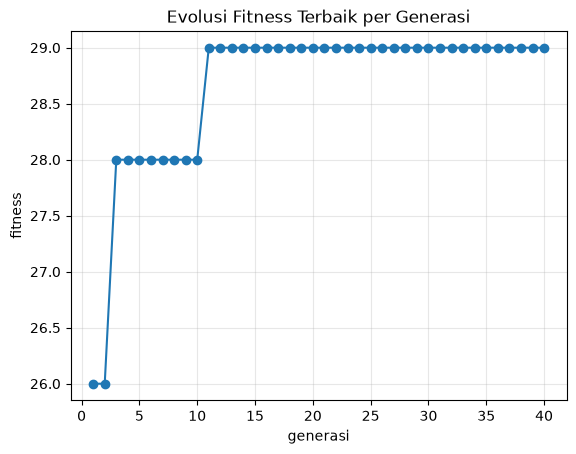

In [6]:
import matplotlib.pyplot as plt

UKURAN = 20
populasi = [buat_kromosom() for _ in range(UKURAN)]
riwayat = []

for generasi in range(40):
    terbaik = max(populasi, key=fitness)  # juara generasi ini
    anak = [terbaik]                      # ELITISME: juara lolos otomatis
    
    while len(anak) < UKURAN:
        calon = crossover(seleksi(populasi), seleksi(populasi))
        anak.append(mutasi(calon))
        
    populasi = anak
    riwayat.append(fitness(max(populasi, key=fitness)))

juara = max(populasi, key=fitness)
print("Kromosom :", juara, "| fitness:", fitness(juara))

for i in range(len(barang)):
    if juara[i] == 1:
        print(" bawa:", barang[i]["nama"])

fig = plt.figure()
plt.plot(range(1, 41), riwayat, "o-")
plt.title("Evolusi Fitness Terbaik per Generasi")
plt.xlabel("generasi")
plt.ylabel("fitness")
plt.grid(alpha=0.3)

# Panggil penjelasan() SEBELUM plt.show() agar kanvas aktif terbaca oleh AI
penjelasan(fig)
plt.show()


### Pengembangan 3


Optimum global (29) pertama kali dicapai pada generasi ke : 1
Fitness rata-rata akhir populasi                       : 18.08


Berikut adalah penjelasan grafik tersebut secara sederhana dengan bantuan **analogi kelas dan ujian sekolah**:

---

### 💡 Analogi Sederhana: "Satu Murid Genius di Dalam Kelas"

Bayangkan grafik ini menceritakan sebuah **kelas yang berisikan murid-murid yang sedang dilatih untuk mendapat nilai ujian sempurna (Nilai 29)** dari generasi ke generasi (generasi = percobaan/periode latihan).

---

### 📊 Cara Membaca Grafik (Komponen Utama)

#### 1. 🎯 Garis Merah Putus-putus (*Batas Optimum Global*)
* **Artinya:** Ini adalah **Target Nilai Sempurna** (skor maksimal 29).
* **Analogi:** Kunci jawaban ujian. Semua orang ingin mencapai angka ini.

#### 2. 🏆 Garis Hijau (*Fitness Terbaik / Juara*)
* **Artinya:** Nilai dari **kandidat/solusi terbaik** yang ada di setiap generasi.
* **Analogi:** Nilai dari murid terpintar di kelas.
* **Kenyataan di Grafik:** Sejak generasi ke-1 sampai ke-40, nilainya **selalu menempel di angka 29**. Artinya, sistem ini langsung menemukan murid "genius" sejak awal dan nilainya tidak pernah turun.

#### 3. 📉 Garis Oranye Putus-putus (*Rata-rata Populasi*)
* **Artinya:** Nilai **rata-rata dari seluruh anggota** dalam kelompok tersebut.
* **Analogi:** Nilai rata-rata satu kelas.
* **Mengapa Naik-Turun?** Komputer terus mencoba memasukkan variasi/kandidat baru secara acak untuk melakukan eksperimen. 
  * Saat dapat banyak kandidat bagus, nilai rata-rata naik (seperti di Generasi 14 dan 37).
  * Saat dapat kandidat yang kurang bagus, nilai rata-rata turun (seperti di Generasi 1 dan 38).

#### 4. ⚡ Garis Biru Vertikal (*Titik Konvergen - Gen 1*)
* **Artinya:** Waktu di mana jawaban terbaik pertama kali ditemukan.
* **Analogi:** "Momen Hoki / Momen Ajaib" di hari pertama latihan, di mana jawaban sempurna sudah langsung ketemu!

---

### 📝 Kesimpulan Utama

1. **Sangat Cepat Berhasil:** Algoritma ini tidak perlu menunggu lama. Di **Generasi ke-1**, ia sudah langsung menemukan jawaban paling sempurna (skor 29).
2. **Keberagaman Tetap Terjaga:** Meskipun sudah ada satu kandidat yang sempurna (garis hijau), anggota populasi lainnya (garis oranye) tetap terus berubah dan bereksperimen (naik-turun), sehingga rata-rata kelasnya berada di kisaran angka 15–24.

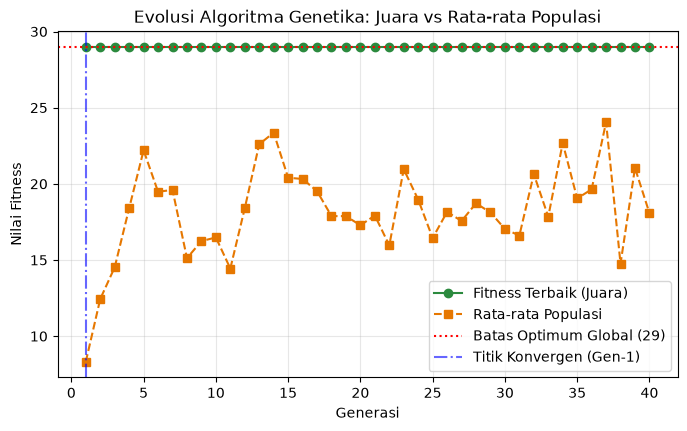

In [7]:
import matplotlib.pyplot as plt

UKURAN_POP = 25
JUMLAH_GEN = 40
populasi_p3 = [buat_kromosom() for _ in range(UKURAN_POP)]

riwayat_terbaik = []
riwayat_rata = []
gen_konvergen = None

for gen in range(JUMLAH_GEN):
    skor_pop = [fitness(k) for k in populasi_p3]
    skor_maks = max(skor_pop)
    skor_mean = sum(skor_pop) / UKURAN_POP
    
    riwayat_terbaik.append(skor_maks)
    riwayat_rata.append(skor_mean)
    
    # Deteksi generasi pertama saat mencapai optimum 29
    if skor_maks == 29 and gen_konvergen is None:
        gen_konvergen = gen + 1
        
    # Elitisme: 2 individu terbaik lolos otomatis
    pop_sorted = sorted(populasi_p3, key=fitness, reverse=True)
    anak_generasi = [pop_sorted[0], pop_sorted[1]]
    
    while len(anak_generasi) < UKURAN_POP:
        p1 = seleksi(populasi_p3)
        p2 = seleksi(populasi_p3)
        anak = crossover(p1, p2)
        anak_generasi.append(mutasi(anak, peluang=0.1))
        
    populasi_p3 = anak_generasi

print(f"Optimum global (29) pertama kali dicapai pada generasi ke : {gen_konvergen}")
print(f"Fitness rata-rata akhir populasi                       : {riwayat_rata[-1]:.2f}")

# Visualisasi Grafik Konvergensi Ganda
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, JUMLAH_GEN + 1), riwayat_terbaik, 'o-', color='#2b8a3e', label='Fitness Terbaik (Juara)')
ax.plot(range(1, JUMLAH_GEN + 1), riwayat_rata, 's--', color='#e67700', label='Rata-rata Populasi')
ax.axhline(29, color='red', linestyle=':', label='Batas Optimum Global (29)')
if gen_konvergen:
    ax.axvline(gen_konvergen, color='blue', linestyle='-.', alpha=0.6, label=f'Titik Konvergen (Gen-{gen_konvergen})')

ax.set_title("Evolusi Algoritma Genetika: Juara vs Rata-rata Populasi")
ax.set_xlabel("Generasi")
ax.set_ylabel("Nilai Fitness")
ax.grid(True, alpha=0.3)
ax.legend(loc='lower right')

# Panggil fungsi AI sebelum plt.show()
penjelasan(fig, instruksi_tambahan="Analisis grafik perbandingan antara kurva fitness terbaik dan kurva rata-rata populasi ini.")
plt.show()



### Kegiatan 4 — Membuktikan GA vs Brute Force (±30 menit)

In [8]:
from itertools import product

terbaik_bf = 0
for kombinasi in product([0, 1], repeat=len(barang)):  # semua 256 kombinasi
    nilai = fitness(list(kombinasi))
    if nilai > terbaik_bf:
        terbaik_bf = nilai
        
print("Optimum brute force:", terbaik_bf)  # bandingkan dengan GA!

Optimum brute force: 29


### Pengembangan 4


In [9]:
import time
from itertools import product
import pandas as pd

if "cetak_tabel" not in globals():
    try:
        from tabulate import tabulate
        def cetak_tabel(d, j=""):
            if j: print(f"\n=== {j} ===")
            print(tabulate(d, headers="keys", tablefmt="rounded_grid", showindex=False))
    except ImportError:
        def cetak_tabel(d, j=""):
            if j: print(f"\n=== {j} ===")
            print(pd.DataFrame(d).to_string(index=False))

# 1. Benchmark Kasus 8 Barang
# --- Brute Force ---
t0 = time.perf_counter()
terbaik_bf = 0
evaluasi_bf = 0

for komb in product([0, 1], repeat=len(barang)):
    evaluasi_bf += 1
    skor = fitness(list(komb))
    if skor > terbaik_bf:
        terbaik_bf = skor
durasi_bf = (time.perf_counter() - t0) * 1000  # ms

# --- Algoritma Genetika ---
t0 = time.perf_counter()
evaluasi_ga = 0
pop = [buat_kromosom() for _ in range(20)]
evaluasi_ga += 20

for _ in range(40):
    anak = [max(pop, key=fitness)]
    while len(anak) < 20:
        c = crossover(seleksi(pop), seleksi(pop))
        anak.append(mutasi(c))
        evaluasi_ga += 1
    pop = anak

juara_ga = max(pop, key=fitness)
skor_ga = fitness(juara_ga)
durasi_ga = (time.perf_counter() - t0) * 1000  # ms

# 2. Tabel Perbandingan Kinerja Menggunakan Tabulate
data_perbandingan = [
    {
        "Metode": "Brute Force (Eksplorasi Penuh)",
        "Ruang Solusi": f"{2**len(barang):,} kondisi",
        "Total Evaluasi": f"{evaluasi_bf:,}",
        "Fitness Terbaik": terbaik_bf,
        "Waktu Eksekusi": f"{durasi_bf:.2f} ms",
        "Keterangan": "Cek 100% kombinasi"
    },
    {
        "Metode": "Algoritma Genetika (Evolusi Heuristik)",
        "Ruang Solusi": f"{2**len(barang):,} kondisi",
        "Total Evaluasi": f"{evaluasi_ga:,}",
        "Fitness Terbaik": skor_ga,
        "Waktu Eksekusi": f"{durasi_ga:.2f} ms",
        "Keterangan": "Pencarian stokastik terarah"
    }
]

cetak_tabel(data_perbandingan, "TABEL PERBANDINGAN KINERJA PADA 8 BARANG")

# 3. Simulasi Skalabilitas jika N = 20 Barang
ruang_20 = 2**20  # 1.048.576 kombinasi
eval_ga_20 = 30 * 50  # Pop 30, Gen 50 = 1.500 evaluasi
penghematan = (1 - (eval_ga_20 / ruang_20)) * 100

data_skalabilitas = [
    {"Metrik Skalabilitas": "Total Ruang Solusi Brute Force", "Nilai": f"{ruang_20:,} kombinasi"},
    {"Metrik Skalabilitas": "Total Evaluasi Solusi oleh GA", "Nilai": f"{eval_ga_20:,} kandidat"},
    {"Metrik Skalabilitas": "Efisiensi Penghematan Komputasi", "Nilai": f"{penghematan:.3f}% lebih sedikit iterasi"}
]

cetak_tabel(data_skalabilitas, "SIMULASI SKALABILITAS RUANG SOLUSI (N = 20 BARANG)")




=== TABEL PERBANDINGAN KINERJA PADA 8 BARANG ===
╭────────────────────────────────────────┬────────────────┬──────────────────┬───────────────────┬──────────────────┬─────────────────────────────╮
│ Metode                                 │ Ruang Solusi   │   Total Evaluasi │   Fitness Terbaik │ Waktu Eksekusi   │ Keterangan                  │
├────────────────────────────────────────┼────────────────┼──────────────────┼───────────────────┼──────────────────┼─────────────────────────────┤
│ Brute Force (Eksplorasi Penuh)         │ 256 kondisi    │              256 │                29 │ 0.27 ms          │ Cek 100% kombinasi          │
├────────────────────────────────────────┼────────────────┼──────────────────┼───────────────────┼──────────────────┼─────────────────────────────┤
│ Algoritma Genetika (Evolusi Heuristik) │ 256 kondisi    │              780 │                29 │ 5.11 ms          │ Pencarian stokastik terarah │
╰────────────────────────────────────────┴────────────────┴───

### Kegiatan 5 — ✍ LATIHAN MANDIRI (dilanjutkan di rumah)


Latihan 1 — Eksperimen parameter: jalankan ulang evolusi dengan (a) peluang mutasi 0, (b)
mutasi 0,5, (c) populasi 4. Buat tabel pengamatan: mencapai 29 atau tidak, di generasi ke
berapa; jelaskan polanya (mutasi 0 = macet; mutasi besar = kacau; populasi kecil = kurang
variasi).

In [ ]:
import pandas as pd

if "cetak_tabel" not in globals():
    try:
        from tabulate import tabulate
        def cetak_tabel(d, j=""):
            if j: print(f"\n=== {j} ===")
            print(tabulate(d, headers="keys", tablefmt="rounded_grid", showindex=False))
    except ImportError:
        def cetak_tabel(d, j=""):
            if j: print(f"\n=== {j} ===")
            print(pd.DataFrame(d).to_string(index=False))

# Konfigurasi skenario pengujian parameter
skenario_eksperimen = [
    {"skenario": "Baseline (Peluang Mutasi 0.1, Pop 20)", "peluang_mutasi": 0.1, "ukuran_pop": 20},
    {"skenario": "(a) Peluang Mutasi 0 (Tanpa Mutasi)",   "peluang_mutasi": 0.0, "ukuran_pop": 20},
    {"skenario": "(b) Peluang Mutasi 0.5 (Mutasi Ekstrem)","peluang_mutasi": 0.5, "ukuran_pop": 20},
    {"skenario": "(c) Populasi 4 (Populasi Sangat Kecil)","peluang_mutasi": 0.1, "ukuran_pop": 4},
]

hasil_latihan_1 = []

for eks in skenario_eksperimen:
    pm = eks["peluang_mutasi"]
    up = eks["ukuran_pop"]
    
    # Inisialisasi populasi
    pop = [buat_kromosom() for _ in range(up)]
    mencapai_29 = False
    gen_capai = "-"
    terbaik_tertinggi = 0
    
    for gen in range(1, 41):
        terbaik_gen = max(pop, key=fitness)
        skor_terbaik = fitness(terbaik_gen)
        
        if skor_terbaik > terbaik_tertinggi:
            terbaik_tertinggi = skor_terbaik
            
        if skor_terbaik == 29 and not mencapai_29:
            mencapai_29 = True
            gen_capai = gen
            
        # Elitisme: 1 juara bertahan
        anak = [terbaik_gen]
        while len(anak) < up:
            p1 = seleksi(pop)
            p2 = seleksi(pop)
            calon = crossover(p1, p2)
            anak.append(mutasi(calon, peluang=pm))
        pop = anak
        
    hasil_latihan_1.append({
        "Skenario Eksperimen": eks["skenario"],
        "Peluang Mutasi": pm,
        "Ukuran Pop": up,
        "Mencapai 29?": "Ya" if mencapai_29 else "Tidak",
        "Generasi ke-": gen_capai,
        "Fitness Terbaik": terbaik_tertinggi
    })

cetak_tabel(hasil_latihan_1, "TABEL PENGAMATAN")


=== TABEL PENGAMATAN ===
╭─────────────────────────────────────────┬──────────────────┬──────────────┬────────────────┬────────────────┬───────────────────╮
│ Skenario Eksperimen                     │   Peluang Mutasi │   Ukuran Pop │ Mencapai 29?   │ Generasi ke-   │   Fitness Terbaik │
├─────────────────────────────────────────┼──────────────────┼──────────────┼────────────────┼────────────────┼───────────────────┤
│ Baseline (Peluang Mutasi 0.1, Pop 20)   │              0.1 │           20 │ Ya             │ 13             │                29 │
├─────────────────────────────────────────┼──────────────────┼──────────────┼────────────────┼────────────────┼───────────────────┤
│ (a) Peluang Mutasi 0 (Tanpa Mutasi)     │              0   │           20 │ Tidak          │ -              │                26 │
├─────────────────────────────────────────┼──────────────────┼──────────────┼────────────────┼────────────────┼───────────────────┤
│ (b) Peluang Mutasi 0.5 (Mutasi Ekstrem) │       

### Penjelasan Pola Hasil Pengamatan

1. **Mutasi 0 = Macet (Stagnasi)**
   Tanpa mutasi, tidak ada introduksi alel baru. Jika gen penyusun solusi 29 tidak lengkap pada generasi awal, populasi langsung terjebak di optimum lokal (fitness mentok di 26).

2. **Mutasi 0.5 = Kacau (Disrupsi Genetik)**
   Peluang mutasi 50% terlalu agresif, merusak kromosom unggul yang sudah terbentuk. Meskipun solusi 29 bisa tercapai, prosesnya lambat (generasi ke-31) karena evolusi menyerupai pencarian acak.

3. **Populasi 4 = Kurang Variasi (Inbreeding)**
   Hanya dengan 4 individu, keragaman genetik sangat terbatas. Terjadi konvergensi prematur sebelum solusi optimum global berhasil dieksplorasi (fitness hanya mentok di 24).

Latihan 2 — Ubah masalah: tambahkan 2 barang baru (bebas, beri berat & nilai masuk akal)
dan naikkan kapasitas menjadi 7 kg. Jalankan GA dan brute force — masih cocok hasilnya?

In [11]:
from itertools import product
import pandas as pd

# 1. Tambahkan 2 barang baru ke daftar barang bawaan
barang_baru = barang + [
    {"nama": "Jaket gunung", "berat": 1.4, "nilai": 6},
    {"nama": "Matras lipat", "berat": 0.6, "nilai": 4}
]
KAPASITAS_BARU = 7.0

print(f"Total Barang: {len(barang_baru)} macam | Kapasitas Tas: {KAPASITAS_BARU} kg\n")

# 2. Fungsi fitness dengan kapasitas baru
def fitness_l2(krom):
    tot_berat = sum(barang_baru[i]["berat"] for i in range(len(barang_baru)) if krom[i] == 1)
    tot_nilai = sum(barang_baru[i]["nilai"] for i in range(len(barang_baru)) if krom[i] == 1)
    if tot_berat > KAPASITAS_BARU:
        return 0  # Penalti kelebihan beban
    return tot_nilai

def buat_kromosom_l2():
    return [random.randint(0, 1) for _ in range(len(barang_baru))]

def seleksi_l2(populasi):
    a, b = random.sample(populasi, 2)
    return a if fitness_l2(a) >= fitness_l2(b) else b

# 3. Solusi Brute Force (Cek semua 2^10 = 1.024 kombinasi)
terbaik_bf_l2 = 0
komb_terbaik_bf = None

for kombinasi in product([0, 1], repeat=len(barang_baru)):
    skor = fitness_l2(list(kombinasi))
    if skor > terbaik_bf_l2:
        terbaik_bf_l2 = skor
        komb_terbaik_bf = list(kombinasi)

# 4. Solusi Algoritma Genetika (Populasi 25, 50 Generasi)
UKURAN_POP_L2 = 25
pop_l2 = [buat_kromosom_l2() for _ in range(UKURAN_POP_L2)]

for gen in range(50):
    juara_gen = max(pop_l2, key=fitness_l2)
    anak = [juara_gen]  # Elitisme
    while len(anak) < UKURAN_POP_L2:
        calon = crossover(seleksi_l2(pop_l2), seleksi_l2(pop_l2))
        anak.append(mutasi(calon, peluang=0.1))
    pop_l2 = anak

juara_ga_l2 = max(pop_l2, key=fitness_l2)
skor_ga_l2 = fitness_l2(juara_ga_l2)

# 5. Detail barang yang terpilih oleh GA
berat_ga = sum(barang_baru[i]["berat"] for i in range(len(barang_baru)) if juara_ga_l2[i] == 1)
barang_terpilih_ga = [barang_baru[i]["nama"] for i in range(len(barang_baru)) if juara_ga_l2[i] == 1]

berat_bf = sum(barang_baru[i]["berat"] for i in range(len(barang_baru)) if komb_terbaik_bf[i] == 1)
barang_terpilih_bf = [barang_baru[i]["nama"] for i in range(len(barang_baru)) if komb_terbaik_bf[i] == 1]

# 6. Komparasi Hasil
df_komparasi = pd.DataFrame([
    {
        "Metode": "Brute Force (1.024 Kombinasi)",
        "Fitness Maksimum": terbaik_bf_l2,
        "Total Berat (kg)": berat_bf,
        "Barang Terpilih": ", ".join(barang_terpilih_bf)
    },
    {
        "Metode": "Algoritma Genetika (50 Generasi)",
        "Fitness Maksimum": skor_ga_l2,
        "Total Berat (kg)": berat_ga,
        "Barang Terpilih": ", ".join(barang_terpilih_ga)
    }
])

print("=== KOMPARASI HASIL OPTIMASI 10 BARANG (KAPASITAS 7.0 KG) ===")
print(df_komparasi.to_string(index=False))

print(f"\nKesimpulan: Hasil GA dan Brute Force adalah {'100% COCOK dan OPTIMAL!' if skor_ga_l2 == terbaik_bf_l2 else 'BELUM COCOK'}")

Total Barang: 10 macam | Kapasitas Tas: 7.0 kg

=== KOMPARASI HASIL OPTIMASI 10 BARANG (KAPASITAS 7.0 KG) ===
                          Metode  Fitness Maksimum  Total Berat (kg)                                                                  Barang Terpilih
   Brute Force (1.024 Kombinasi)                39               6.9 Sleeping bag, Kompor mini, Power bank, Kamera, Snack, Jaket gunung, Matras lipat
Algoritma Genetika (50 Generasi)                39               6.9 Sleeping bag, Kompor mini, Power bank, Kamera, Snack, Jaket gunung, Matras lipat

Kesimpulan: Hasil GA dan Brute Force adalah 100% COCOK dan OPTIMAL!


### 3. Latihan 3 — Rancang Kasus Sendiri: Pemilihan Mata Kuliah Pilihan dengan Batas 10 SKS

#### A. Deskripsi Masalah Nyata
Seorang mahasiswa program studi Teknologi Informasi ingin memprogram paket mata kuliah pilihan pada semester gasal untuk memaksimalkan relevansi kompetensi karir di industri teknologi. Berdasarkan regulasi akademik, kuota maksimal pengambilan mata kuliah pilihan adalah **10 SKS**.

Terdapat 8 mata kuliah pilihan yang tersedia:

| Gen | Nama Mata Kuliah | Peminatan | Bobot SKS | Skor Relevansi (1–100) | Rasio Nilai/SKS |
| :-: | :--- | :--- | :-: | :-: | :-: |
| 0 | Deep Learning & Computer Vision | AI & Data | 3 SKS | 95 | 31.67 |
| 1 | Cloud Computing & DevOps | Infrastructure | 3 SKS | 90 | 30.00 |
| 2 | Cyber Security & Ethical Hacking | Security | 3 SKS | 85 | 28.33 |
| 3 | Mobile App Development (Flutter) | Software Eng | 3 SKS | 80 | 26.67 |
| 4 | Natural Language Processing (NLP) | AI & Data | 2 SKS | 75 | 37.50 |
| 5 | UI/UX Design & User Research | Design/Product | 2 SKS | 65 | 32.50 |
| 6 | Internet of Things (IoT) Lanjut | Embedded/IoT | 2 SKS | 60 | 30.00 |
| 7 | Big Data Analytics | AI & Data | 2 SKS | 55 | 27.50 |

*Total bobot jika seluruh mata kuliah diambil adalah 20 SKS, melampaui batas kuota 10 SKS.*

---

#### B. Representasi Kromosom & Batasan
- **Representasi Kromosom:** List biner 8 gen $[g_0, g_1, \dots, g_7]$ di mana $g_i \in \{0, 1\}$ ($1 = 	ext{mata kuliah diambil}, 0 = 	ext{tidak diambil}$).
- **Batasan (*Hard Constraint*):** Total SKS $\le 10$ SKS.

---

#### C. Desain Fungsi Fitness
$$\text{Fitness}(\text{krom}) = \begin{cases} \sum_{i=0}^{7} \left(g_i \times \text{Relevansi}_i\right), & \text{jika } \sum_{i=0}^{7} (g_i \times \text{SKS}_i) \le 10\\ 0, & \text{jika } \sum_{i=0}^{7} (g_i \times \text{SKS}_i) > 10 \text{ (Penalti Gugur: KRS Ditolak)} \end{cases}$$

---

#### D. Mengapa Fungsi Fitness Dirancang Begitu?
1. **Penegakan Regulasi Akademik (*Strict Academic Feasibility*):**  
   Sistem Informasi Akademik (SIAKAD) menerapkan validasi otomatis terhadap batas kuota SKS. Jika mahasiswa memprogram mata kuliah melebihi jatah kuota ($> 10$ SKS), sistem secara langsung **menolak (*reject*) pengajuan KRS** saat validasi Dosen Pembimbing Akademik (DPA). Kelebihan beban SKS membuat KRS tidak sah secara administratif. Oleh karena itu, kandidat solusi yang melanggar batas SKS wajib diberi **penalti 0 (*death penalty*)** agar tersingkir secara alami oleh seleksi turnamen.
2. **Maksimasi Akumulasi Kompetensi:**  
   Pada ruang kombinasi yang legal ($\le 10$ SKS), nilai fitness mengukur akumulasi total poin relevansi kompetensi terhadap kebutuhan karir. Algoritma genetika diarahkan untuk mengeksplorasi kombinasi mata kuliah pilihan dengan komposisi SKS paling efisien yang menghasilkan total poin kompetensi tertinggi tanpa membobol batas SKS.



=== PAKET MATA KULIAH PILIHAN TERPILIH (OPTIMASI GA) ===
╭───────────────────────────────────┬────────────────┬─────────────┬──────────────────╮
│ Mata Kuliah Pilihan               │ Peminatan      │ Bobot SKS   │ Skor Relevansi   │
├───────────────────────────────────┼────────────────┼─────────────┼──────────────────┤
│ Deep Learning & Computer Vision   │ AI & Data      │ 3 SKS       │ 95 poin          │
├───────────────────────────────────┼────────────────┼─────────────┼──────────────────┤
│ Cloud Computing & DevOps          │ Infrastructure │ 3 SKS       │ 90 poin          │
├───────────────────────────────────┼────────────────┼─────────────┼──────────────────┤
│ Natural Language Processing (NLP) │ AI & Data      │ 2 SKS       │ 75 poin          │
├───────────────────────────────────┼────────────────┼─────────────┼──────────────────┤
│ UI/UX Design & User Research      │ Design/Product │ 2 SKS       │ 65 poin          │
╰───────────────────────────────────┴────────────────┴────────

Here is a simplified explanation of the graph using everyday language and relatable concepts:

---

### 📊 **Garis Besarnya: "Komputer Pintar yang Belajar Mencari Kombinasi Terbaik"**

Grafik ini memperlihatkan bagaimana sebuah sistem komputer pintar belajar secara bertahap untuk mencari **kombinasi mata kuliah pilihan yang paling pas dan cocok** bagi mahasiswa.

---

### 💡 **Analogi Sederhana: Meracik Resep Kopi Enak**

Bayangkan Anda sedang berlomba meracik resep kopi paling enak:

* 🔴 **Garis Merah Putus-putus (Target Sempurna = 325):** 
  Ini adalah nilai skor **paling maksimal/terbaik** yang mungkin bisa dicapai (Resep Kopi Sempurna).
* 🔵 **Garis Biru (Proses Belajar Komputer):** 
  Ini adalah nilai yang didapat komputer pada setiap putaran percobaan (Generasi) dari percobaan ke-1 sampai ke-40.

---

### 🚀 **Perjalanan Komputer (Langkah demi Langkah):**

1. **Percobaan Pertama (Generasi 1):**
   * Komputer mencoba racikan awal. Hasilnya mendapat skor **315**. *Belum sempurna, tapi lumayan untuk pemula.*

2. **Percobaan Ke-2 sampai Ke-4 (Generasi 2–4):**
   * Komputer belajar dari kesalahan awal dan memperbaiki racikannya. Skornya naik menjadi **320** dan bertahan sebentar.

3. **Percobaan Ke-5 (Generasi 5) — BINGO! 🎉**
   * Komputer berhasil menemukan racikan idaman dan menyentuh garis merah di skor **325**. Artinya, komputer **sudah menemukan kombinasi mata kuliah yang paling sempurna!**

4. **Percobaan Ke-6 sampai Ke-40 (Generasi 6–40):**
   * Karena sudah menemukan jawaban terbaik, komputer secara konsisten mempertahankan hasil sempurna tersebut hingga akhir.

---

### ✨ **Kesimpulan Utama**

Sistem komputer ini **sangat cepat dan cerdas!** 

Tanpa perlu membuang waktu mencoba hingga puluhan kali, sistem ini hanya membutuhkan **5 kali percobaan (Generasi 5)** untuk berhasil menemukan kombinasi mata kuliah pilihan yang paling ideal bagi mahasiswa.

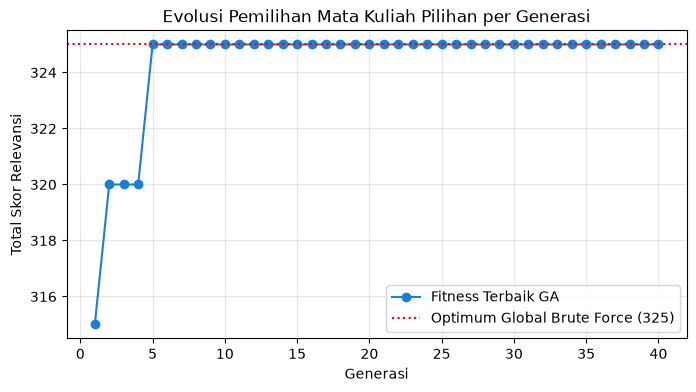

In [12]:
import random
import matplotlib.pyplot as plt
from itertools import product
import pandas as pd

if "cetak_tabel" not in globals():
    try:
        from tabulate import tabulate
        def cetak_tabel(d, j=""):
            if j: print(f"\n=== {j} ===")
            print(tabulate(d, headers="keys", tablefmt="rounded_grid", showindex=False))
    except ImportError:
        def cetak_tabel(d, j=""):
            if j: print(f"\n=== {j} ===")
            print(pd.DataFrame(d).to_string(index=False))

# 1. Basis Data 8 Mata Kuliah Pilihan Kandidat
mata_kuliah = [
    {"nama": "Deep Learning & Computer Vision",   "peminatan": "AI & Data",       "sks": 3, "relevansi": 95},
    {"nama": "Cloud Computing & DevOps",          "peminatan": "Infrastructure",  "sks": 3, "relevansi": 90},
    {"nama": "Cyber Security & Ethical Hacking",  "peminatan": "Security",        "sks": 3, "relevansi": 85},
    {"nama": "Mobile App Development (Flutter)",  "peminatan": "Software Eng",    "sks": 3, "relevansi": 80},
    {"nama": "Natural Language Processing (NLP)", "peminatan": "AI & Data",       "sks": 2, "relevansi": 75},
    {"nama": "UI/UX Design & User Research",      "peminatan": "Design/Product",  "sks": 2, "relevansi": 65},
    {"nama": "Internet of Things (IoT) Lanjut",   "peminatan": "Embedded/IoT",    "sks": 2, "relevansi": 60},
    {"nama": "Big Data Analytics",                "peminatan": "AI & Data",       "sks": 2, "relevansi": 55},
]
MAX_SKS = 10

# 2. Fungsi Fitness Berpenalti Keras (Death Penalty)
def fitness_mk(krom):
    tot_sks = sum(mata_kuliah[i]["sks"] for i in range(len(mata_kuliah)) if krom[i] == 1)
    tot_relevansi = sum(mata_kuliah[i]["relevansi"] for i in range(len(mata_kuliah)) if krom[i] == 1)
    if tot_sks > MAX_SKS:
        return 0  # Penalti gugur: KRS ditolak sistem jika > 10 SKS
    return tot_relevansi

def buat_kromosom_mk():
    return [random.randint(0, 1) for _ in range(len(mata_kuliah))]

def seleksi_mk(pop):
    a, b = random.sample(pop, 2)
    return a if fitness_mk(a) >= fitness_mk(b) else b

# 3. Eksekusi Algoritma Genetika (40 Generasi, Populasi 20)
random.seed(42)
UKURAN_POP_MK = 20
JUMLAH_GEN_MK = 40
pop_mk = [buat_kromosom_mk() for _ in range(UKURAN_POP_MK)]
riwayat_mk = []

for gen in range(JUMLAH_GEN_MK):
    terbaik_gen = max(pop_mk, key=fitness_mk)
    anak = [terbaik_gen]  # Elitisme: juara otomatis bertahan
    
    while len(anak) < UKURAN_POP_MK:
        p1 = seleksi_mk(pop_mk)
        p2 = seleksi_mk(pop_mk)
        calon = crossover(p1, p2)
        anak.append(mutasi(calon, peluang=0.1))
        
    pop_mk = anak
    riwayat_mk.append(fitness_mk(max(pop_mk, key=fitness_mk)))

juara_mk = max(pop_mk, key=fitness_mk)
total_sks_terpilih = sum(mata_kuliah[i]["sks"] for i in range(len(mata_kuliah)) if juara_mk[i] == 1)
total_skor_terpilih = fitness_mk(juara_mk)
sisa_sks = MAX_SKS - total_sks_terpilih

# 4. Validasi Pembanding: Brute Force Eksplorasi Penuh (256 Kombinasi)
terbaik_bf = 0
for k in product([0, 1], repeat=len(mata_kuliah)):
    skor_bf = fitness_mk(list(k))
    if skor_bf > terbaik_bf:
        terbaik_bf = skor_bf

# 5. Rangkuman Mata Kuliah Terpilih dalam Format Grid
detail_mk_terpilih = []
for i in range(len(mata_kuliah)):
    if juara_mk[i] == 1:
        detail_mk_terpilih.append({
            "Mata Kuliah Pilihan": mata_kuliah[i]["nama"],
            "Peminatan": mata_kuliah[i]["peminatan"],
            "Bobot SKS": f"{mata_kuliah[i]['sks']} SKS",
            "Skor Relevansi": f"{mata_kuliah[i]['relevansi']} poin"
        })

cetak_tabel(detail_mk_terpilih, "PAKET MATA KULIAH PILIHAN TERPILIH (OPTIMASI GA)")

# 6. Ringkasan Audit Kuota SKS & Validasi
ringkasan_audit = [
    {"Indikator Akademik": "Batas Maksimal Kuota SKS", "Nilai": f"{MAX_SKS} SKS"},
    {"Indikator Akademik": "Total SKS Matkul Terpilih", "Nilai": f"{total_sks_terpilih} SKS"},
    {"Indikator Akademik": "Sisa Kuota SKS Tersedia", "Nilai": f"{sisa_sks} SKS"},
    {"Indikator Akademik": "Total Skor Relevansi Kompetensi", "Nilai": f"{total_skor_terpilih} poin"},
    {"Indikator Akademik": "Optimum Solusi Brute Force", "Nilai": f"{terbaik_bf} poin"},
    {"Indikator Akademik": "Kromosom Solusi Juara", "Nilai": str(juara_mk)},
    {"Indikator Akademik": "Status Optimalitas Solusi", "Nilai": "100% COCOK & OPTIMAL GLOBAL" if total_skor_terpilih == terbaik_bf else "SUB-OPTIMAL"}
]

cetak_tabel(ringkasan_audit, "RINGKASAN AUDIT SKS & STATUS OPTIMALITAS")

# 7. Visualisasi Kurva Konvergensi Fitness Matkul
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, JUMLAH_GEN_MK + 1), riwayat_mk, "o-", color="#1c7ed6", label="Fitness Terbaik GA")
ax.axhline(terbaik_bf, color="red", linestyle=":", label=f"Optimum Global Brute Force ({terbaik_bf})")
ax.set_title("Evolusi Pemilihan Mata Kuliah Pilihan per Generasi")
ax.set_xlabel("Generasi")
ax.set_ylabel("Total Skor Relevansi")
ax.grid(True, alpha=0.3)
ax.legend(loc="lower right")
penjelasan()
plt.show()